# Notebook 07 — Comparison of Logistic Regression and Gradient_Boosting

**Research topic:** *A Machine Learning Approach to Predicting Retail Investor Dormancy on Digital Investment Platforms*

This notebook compares Logistic Regression and Gradient Boosting on the same stratified test observations. It combines descriptive performance metrics with paired statistical testing.

> **Note:** Result-discussion sections have been added after the main evaluation outputs to explain the observed trade-offs and statistical findings.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    matthews_corrcoef, log_loss, brier_score_loss, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.calibration import calibration_curve
from scipy.stats import chi2_contingency
from statsmodels.stats.contingency_tables import mcnemar

DATA_FILE = Path("outputs/dormancy_modelling_dataset.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20
THRESHOLD = 0.50

df = pd.read_csv(DATA_FILE)
X = df.drop(columns=["customer_id", "dormant"])
y = df["dormant"]

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = [c for c in X.columns if c not in categorical_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)


In [2]:

def evaluate(y_true, pred, prob):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    specificity = tn / (tn + fp) if tn + fp else 0
    return {
        "Accuracy": accuracy_score(y_true,pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true,pred),
        "Precision": precision_score(y_true,pred,zero_division=0),
        "Recall": recall_score(y_true,pred,zero_division=0),
        "Specificity": specificity,
        "F1-score": f1_score(y_true,pred,zero_division=0),
        "ROC-AUC": roc_auc_score(y_true,prob),
        "PR-AUC": average_precision_score(y_true,prob),
        "MCC": matthews_corrcoef(y_true,pred),
        "Log Loss": log_loss(y_true,prob),
        "Brier Score": brier_score_loss(y_true,prob),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn
    }


In [3]:

# Recreate both models
lr_num = Pipeline([("imputer",SimpleImputer(strategy="median")),
                   ("scaler",StandardScaler())])
lr_cat = Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                   ("onehot",OneHotEncoder(handle_unknown="ignore"))])
lr_prep = ColumnTransformer([("num",lr_num,numeric_cols),
                             ("cat",lr_cat,categorical_cols)])
lr = Pipeline([("preprocessor",lr_prep),
               ("classifier",LogisticRegression(
                   C=1.0,class_weight="balanced",
                   solver="liblinear",max_iter=1000,
                   random_state=RANDOM_STATE))])
lr.fit(X_train,y_train)
lr_prob = lr.predict_proba(X_test)[:,1]
lr_pred = (lr_prob>=THRESHOLD).astype(int)

gb_num = Pipeline([("imputer",SimpleImputer(strategy="median"))])
gb_cat = Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                   ("onehot",OneHotEncoder(
                       handle_unknown="ignore",sparse_output=False))])
gb_prep = ColumnTransformer([("num",gb_num,numeric_cols),
                             ("cat",gb_cat,categorical_cols)])
Xt = gb_prep.fit_transform(X_train)
Xv = gb_prep.transform(X_test)
pos = y_train.sum()
neg = len(y_train)-pos
w = np.where(y_train==1,len(y_train)/(2*pos),len(y_train)/(2*neg))
gb = GradientBoostingClassifier(
    n_estimators=200,learning_rate=0.05,max_depth=3,
    min_samples_leaf=20,subsample=0.80,random_state=RANDOM_STATE
)
gb.fit(Xt,y_train,sample_weight=w)
gb_prob = gb.predict_proba(Xv)[:,1]
gb_pred = (gb_prob>=THRESHOLD).astype(int)

lr_results = evaluate(y_test,lr_pred,lr_prob)
gb_results = evaluate(y_test,gb_pred,gb_prob)
comparison = pd.DataFrame(
    [lr_results,gb_results],
    index=["Logistic Regression","Gradient Boosting"]
)
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR/"final_model_comparison.csv")


,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC,MCC,Log Loss,Brier Score,TP,TN,FP,FN
Logistic Regression,0.6166,0.7358,0.0348,0.8590,0.6127,0.0669,0.7866,0.0397,0.1211,0.5248,0.1932,134,5875,3714,22
Gradient Boosting,0.7712,0.7891,0.0542,0.8077,0.7706,0.1015,0.8624,0.0671,0.1703,0.3768,0.1363,126,7389,2200,30


### Results discussion

The table shows a clear trade-off between the two models:

- **Logistic Regression** has higher recall (**0.8590 vs 0.8077**), detecting more of the observed dormant investors, but it also produces many more false positives (**3,714 vs 2,200**).
- **Gradient Boosting** has substantially higher specificity (**0.7706 vs 0.6127**), meaning it is better at correctly identifying non-dormant investors and therefore generates fewer unnecessary dormancy alerts.
- Gradient Boosting also has higher **F1-score (0.1015 vs 0.0669)**, **ROC-AUC (0.8624 vs 0.7866)**, **PR-AUC (0.0671 vs 0.0397)** and **MCC (0.1703 vs 0.1211)**.
- Its lower **log loss (0.3768 vs 0.5248)** and **Brier score (0.1363 vs 0.1932)** indicate better probability estimates on this test set.

The very low precision for both models reflects the strong class imbalance: dormancy is relatively rare compared with non-dormancy. Therefore, accuracy alone would hide an important part of the model behaviour.

## Performance comparison

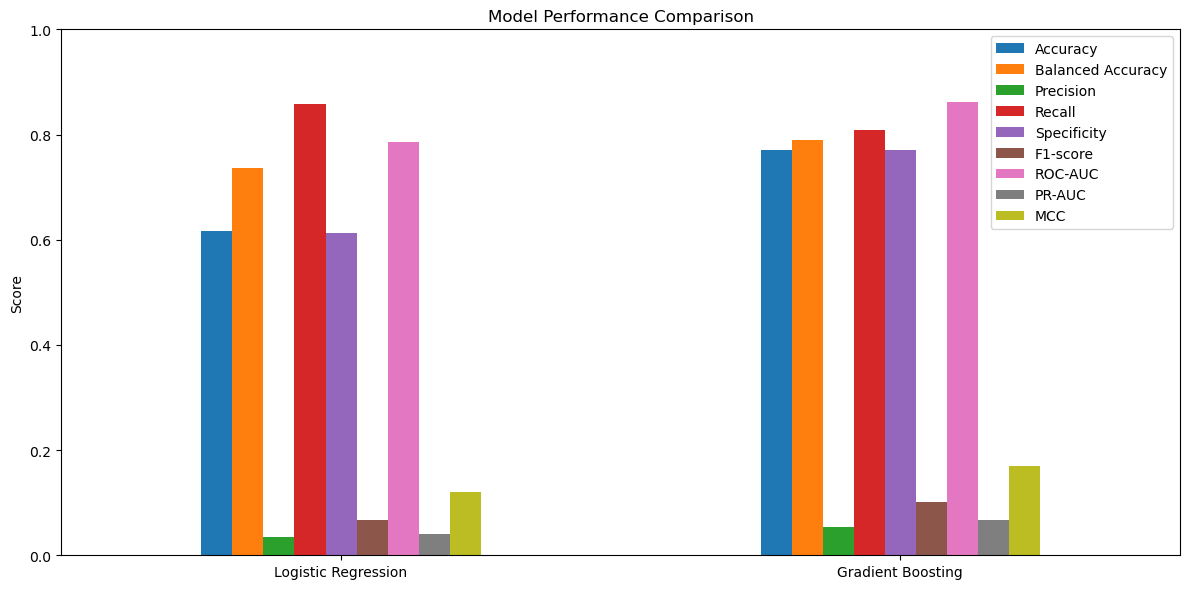

In [4]:

metrics_to_plot = [
    "Accuracy","Balanced Accuracy","Precision","Recall",
    "Specificity","F1-score","ROC-AUC","PR-AUC","MCC"
]
comparison[metrics_to_plot].plot(kind="bar",figsize=(12,6))
plt.ylabel("Score")
plt.ylim(0,1)
plt.title("Model Performance Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"final_model_performance_comparison.png",dpi=300)
plt.show()


### Results discussion

The bar chart makes the trade-off visible. Logistic Regression reaches more dormant investors, as reflected by its higher recall, but Gradient Boosting achieves better overall discrimination and a better balance between precision and recall.

In a retention setting, this difference matters operationally: increasing recall can mean catching more potentially dormant investors, but the much lower specificity of Logistic Regression also means substantially more non-dormant investors would be flagged. The appropriate threshold or model therefore depends on the relative cost of missed dormancy versus unnecessary interventions.

## ROC and Precision-Recall comparison

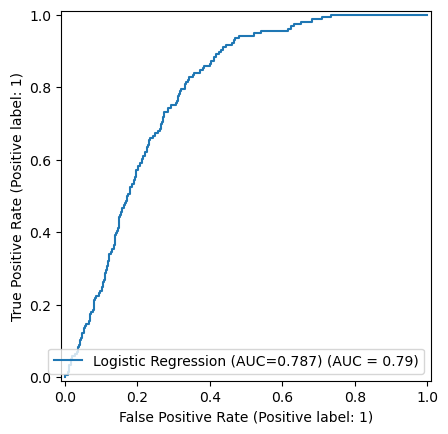

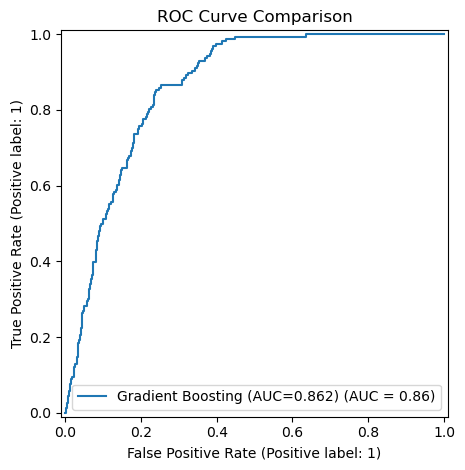

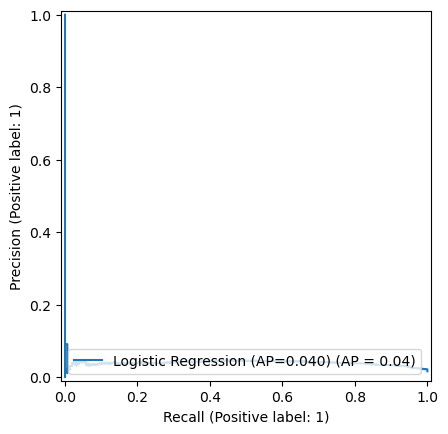

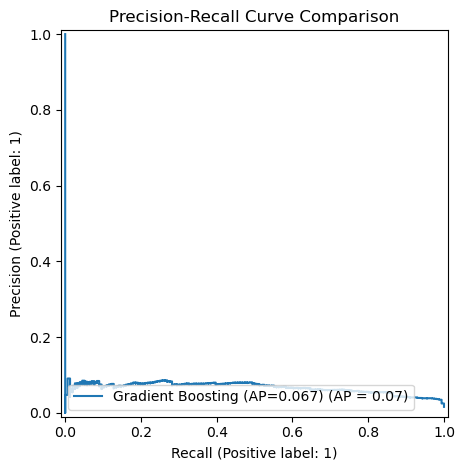

In [5]:

RocCurveDisplay.from_predictions(
    y_test,lr_prob,
    name=f"Logistic Regression (AUC={roc_auc_score(y_test,lr_prob):.3f})")

RocCurveDisplay.from_predictions(
    y_test,gb_prob,
    name=f"Gradient Boosting (AUC={roc_auc_score(y_test,gb_prob):.3f})")

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"final_roc_comparison.png",dpi=300)
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,lr_prob,
    name=f"Logistic Regression (AP={average_precision_score(y_test,lr_prob):.3f})")

PrecisionRecallDisplay.from_predictions(
    y_test,gb_prob,
    name=f"Gradient Boosting (AP={average_precision_score(y_test,gb_prob):.3f})")

plt.title("Precision-Recall Curve Comparison")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"final_precision_recall_comparison.png",dpi=300)
plt.show()


### Results discussion

The ROC and Precision-Recall curves provide a threshold-independent view of model discrimination.

The **ROC-AUC values are 0.7866 for Logistic Regression and 0.8624 for Gradient Boosting**, showing that Gradient Boosting separates the two classes more effectively across thresholds on this test set.

The **PR-AUC values are 0.0397 and 0.0671**, respectively. Because dormancy is a minority class, the Precision-Recall curve is particularly informative: it focuses attention on performance for the positive class rather than allowing the large number of non-dormant observations to dominate the picture.

## McNemar's test

McNemar's test compares the paired error patterns of the two models because both models predict the same test observations. A small p-value indicates evidence that the models make different classifications on the paired observations; it does not by itself establish that one model is universally better.

In [6]:

lr_correct = lr_pred == y_test.to_numpy()
gb_correct = gb_pred == y_test.to_numpy()

table = np.array([
    [np.sum(lr_correct & gb_correct), np.sum(lr_correct & ~gb_correct)],
    [np.sum(~lr_correct & gb_correct), np.sum(~lr_correct & ~gb_correct)]
])

print("Paired correctness table:")
print(table)

result = mcnemar(table,exact=False,correction=True)
print(f"McNemar statistic: {result.statistic:.4f}")
print(f"McNemar p-value: {result.pvalue:.4f}")


Paired correctness table:
[[5847  162]
 [1668 2068]]
McNemar statistic: 1237.7186
McNemar p-value: 0.0000


### Results discussion

The paired correctness table is:

- Both models correct: **5,847** observations
- Logistic Regression correct / Gradient Boosting incorrect: **162**
- Logistic Regression incorrect / Gradient Boosting correct: **1,668**
- Both models incorrect: **2,068**

The McNemar test returns a p-value effectively equal to **0.0000** at the displayed precision. This provides strong statistical evidence that the two models have different paired classification-error patterns on these test observations.

Importantly, this test does **not** by itself say that one model is universally superior. It shows that the models behave differently on the same observations; the direction and practical importance of that difference must be considered using the performance metrics above.

## Paired bootstrap confidence intervals

A paired bootstrap estimates a 95% confidence interval for the difference in F1-score and ROC-AUC. The same resampled test observations are used for both models.

In [7]:

rng = np.random.default_rng(RANDOM_STATE)
B = 2000
y_arr = y_test.to_numpy()
n = len(y_arr)
f1_diff = []
auc_diff = []

for _ in range(B):
    idx = rng.integers(0,n,size=n)
    yb = y_arr[idx]
    if len(np.unique(yb)) < 2:
        continue
    f1_diff.append(f1_score(yb,gb_pred[idx],zero_division=0) - f1_score(yb,lr_pred[idx],zero_division=0))
    
    auc_diff.append(roc_auc_score(yb,gb_prob[idx]) - roc_auc_score(yb,lr_prob[idx]))

bootstrap = pd.DataFrame({
    "Metric":["F1: GB - LR","ROC-AUC: GB - LR"],
    "Mean difference":[np.mean(f1_diff),np.mean(auc_diff)],
    "95% CI lower":[np.percentile(f1_diff,2.5),np.percentile(auc_diff,2.5)],
    "95% CI upper":[np.percentile(f1_diff,97.5),np.percentile(auc_diff,97.5)]
})
display(bootstrap.round(4))
bootstrap.to_csv(OUTPUT_DIR/"paired_bootstrap_comparison.csv",index=False)


,Metric,Mean difference,95% CI lower,95% CI upper
0,F1: GB - LR,0.0346,0.0263,0.0428
1,ROC-AUC: GB - LR,0.0759,0.0537,0.0972


### Results discussion

The paired bootstrap estimates the following differences (**Gradient Boosting − Logistic Regression**):

- **F1-score difference: 0.0346**, with a 95% CI of **[0.0263, 0.0428]**.
- **ROC-AUC difference: 0.0759**, with a 95% CI of **[0.0537, 0.0972]**.

Both intervals are entirely above zero in this resampling analysis. This indicates that the observed advantages in F1-score and ROC-AUC are not concentrated around zero for the sampled test-set variation.

The confidence intervals quantify uncertainty around these observed differences; they should be interpreted as evidence from this test sample rather than as a guarantee that the same differences will occur on every future population or dataset.

## Interpretation and impact

The model comparison helps determine which modelling approach provides more useful evidence for identifying investors at risk of becoming dormant. A model with higher recall may identify more dormant investors for potential retention activity, while a model with higher precision may produce more targeted interventions.

The final interpretation should therefore consider the platform's costs of missed dormant investors versus unnecessary interventions. Statistical significance should be considered alongside practical effect size and business relevance.

The results show two different modelling profiles rather than a single metric telling the whole story.

**Logistic Regression**
- Recall: **0.8590**
- Specificity: **0.6127**
- F1-score: **0.0669**
- ROC-AUC: **0.7866**
- PR-AUC: **0.0397**

This model identifies a larger proportion of the observed dormant investors, but at the cost of substantially more false-positive alerts.

**Gradient Boosting**
- Recall: **0.8077**
- Specificity: **0.7706**
- F1-score: **0.1015**
- ROC-AUC: **0.8624**
- PR-AUC: **0.0671**

This model detects slightly fewer dormant investors, but it reduces false positives considerably and provides stronger overall discrimination and better probability-quality metrics on this test set.

### Practical implication

For a dormancy intervention programme, the choice of operating point should be tied to the business cost of **missing a dormant investor** versus **contacting a non-dormant investor unnecessarily**. The results do not establish a universal best choice; instead, they provide evidence for selecting a model and decision threshold according to the platform's intervention strategy.

Because the positive class is highly imbalanced, future evaluation should continue to emphasise **recall, precision, F1-score, PR-AUC, specificity and calibration/probability metrics**, rather than relying on accuracy alone.

### Statistical conclusion

McNemar's test indicates that the models have significantly different paired error patterns on this test set, while the paired bootstrap intervals indicate positive observed differences in both F1-score and ROC-AUC. Together, these analyses add statistical context to the descriptive metric comparison.